In [2]:
# Generelle moduler og funksjonsbeskrivelser brukt i forelesningen
from numpy import sin, cos, pi, exp, angle, abs, unwrap, log10
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
from IPython.display import Audio

plt.rcParams["figure.figsize"] = [8.00, 4.5]
plt.rcParams["figure.autolayout"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.xmargin"] = 0.0

%matplotlib inline

# Enable importing from modules in top-level directory
from sys import path
if path[0] != '..': path.insert(0, '..')

<img src="figurer/NTNU_logo_vertical.svg" align="left" width="30%">
<br clear="all" />
<br></br>

# Kvantisering

* **Emne: AIS2102 - Dynamiske system**
* ***dato***: 22. januar 2025
* **Foreleser: Kai Erik Hoff**

# Ideell sampling

* Perfekt diskretisering av et signal $u(t)$ der hver sample $u[k]$ tilsvarer den eksakte verdien $u(t)$ i tidspunktet $t = k \cdot T_s$.

<img src="figurer/ideal_sampling.svg" style="width: 60%; margin-left: 100px">
     


# Analog-til-Digital Omformere (ADC)

* Begrenset til et spenningsintervall $v \in [v_{\text{min}}, v_{\text{max}}]$
    * Mikrokontrollere er typisk unipolare, med en spenningsrekkevidde $v \in [0\text{V}, v_{\text{ref}}]$.
        * Noen typiske verdier for $v_{\text{ref}}$: $5\text{V}$, $3.3\text{V}$

* Diskretisert sample $u[k]$ er en *heltallsverdi** med et  bestemt antall **bits** oppløsning
    * Typisk oppløsning for arduino ADC: $10$ bit
    * Mange andre mikrokontrollere har $12$ bit tilgjengelig.

# Kvantisering
<img src="figurer/Fig3_Quantization.png" style="width: 60%; margin-left: 100px" />

# Kvantiseringssteg

* An A/D converter may only sample with finite precision
    * Limited number of discrete voltage levels available to measure
* The distance between each discrete voltage level is the *quantization step size* $q$:
$$\large q = \frac{v_{\text{max}} - v_{\text{min}}}{2^b}$$
where $b$ is the *bit-depth* of the A/D Converter

<img src="figurer/quantization_staircase.png" style="width: 50%; margin-left: 100px">


## Eksempel:
- En Arduino har en innebygd ADC med $10$ bit oppløsning
- ADC'en opererer i en spenningsområde $v \in [0\text{V}, 5\text{V}]$
- Hva er kvantiseringssteghøyden $q$?
- Hva er den største avrundingsfeilen/kvantiseringsfeilen man kan ha?

- Smallest observable change in voltage:
$$ q = \frac{5V}{2^{10}} = \frac{5V}{1024} \approx 4.89mV$$

# Kvantiseringsfeil 

* Avrunding til nærmeste kvantiseringssteg gir en maksimal avrundingsfeil
$$\max\left(w_q(t_k)\right) = \frac{q}{2}$$

* Vi antar typisk at avrundingsfeilen $w_q[k]$ kan modelleres som ***hvitt uniformt fordelt støy*** med effekt $\sigma_w^2 = \frac{q^2}{12}$

$$w_q[k] \sim \mathcal{U}\left(-\frac{q}{2}, \frac{q}{2} \right)$$

<img src="figurer/quantization_model.png" style="width: 60%; margin-left: 100px" />

## Kvantiseringsstøy i lydsignal

In [7]:
from scipy.io import wavfile
fs, data = wavfile.read("../data/Ecstacy_of_gold_intro.wav")

n_bits = 8 # Number of bits used to represent samples

shift = 16 - n_bits # Number of LSB bits to cut
data = data >> shift # Employ bitwise right shift

Audio(data.T, rate=fs) 

## Code demo

In [38]:
from ipywidgets import interact, IntSlider

V_p = 20

# Hypothetical signal
def x(t): 

    B1 = V_p #Hz
    t_0 = (t[-1]-t[0])/9*4
    s = (t[-1]-t[0])*B1*np.sinc(B1*(t-t_0))*(0.5-0.5*np.cos(2*np.pi*np.arange(len(t))/len(t)))*np.cos(2*pi*100*t)
    return s

def quantize(e: list[float], q: float):
    return np.round(e/q)*q

@interact(bits = IntSlider(min=2, max=12, step=1, value=8))
def quantized_spectrum(bits):

    q = 2*V_p/(2**bits)
    fs = 500
    T = 1
    t_k = np.linspace(0, T, fs*T)
    sigma_q = q**2/12
    
    e_k = quantize(x(t_k), q=q)
    
    plt.magnitude_spectrum(e_k, Fs=fs, scale="dB");
    plt.title("$\\text{SNR} = %.2f \\text{dB}$"%(10*np.log10(V_p/sigma_q)))
    plt.ylim([-100, 1])
    plt.show()

interactive(children=(IntSlider(value=8, description='bits', max=12, min=2), Output()), _dom_classes=('widget-…

#### Notater

Signalet $x(t)$ er i denne illustrasjonen vist som et båndbegrenset signal mellom $90 \text{Hz}$ og $110 \text{Hz}$. Når vi justerer på antall bit oppløsning, ser vi hvordan det "hvite" kvantiseringsstøyet øker eller minker i nivå.

# Hvorfor bry seg om kvantisering?

* Små målefeil kan forsterkes av et enkelte typer tidsdiskrete system

* Klassisk eksempel: støyforsterking i derivasjonsledd

## Kode-eksempel:

* Gitt et kontinuerlig signal $u(t) = \sin(\pi \cdot t)$ der $\frac{du(t)}{dt} =\dot{u}(t) = \pi \cdot \cos(\pi \cdot t)$:
    * Utfør diskretisering av signalet med samplingsfrekvense $f_s = 100 \text{Hz}$, og kvantiseringssteghøyde $q = \frac{1}{100}$

In [ ]:
def quantize(e: list[float], q: float):
    return np.round(e/q)*q

def u(t):
    return sin(pi*t)

def du_dt(t):
    return pi*cos(pi*t)

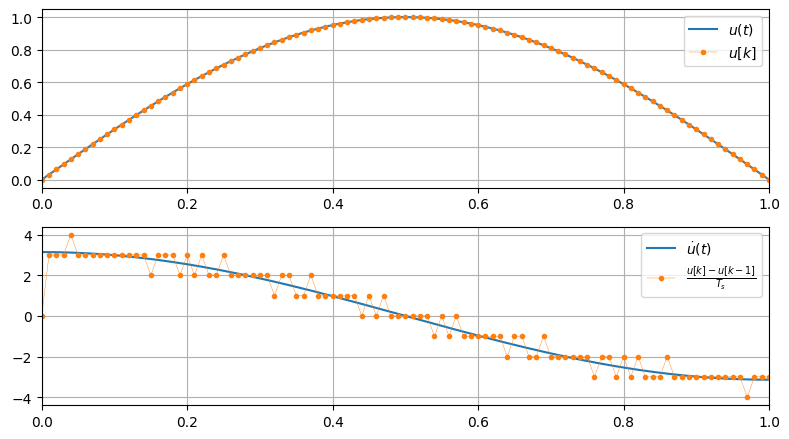

In [35]:
def quantize(e: list[float], q: float):
    return np.round(e/q)*q

def u(t):
    return sin(pi*t)

def du_dt(t):
    return pi*cos(pi*t)


T = 1
fs = 100
q = 0.01
t = np.linspace(0, T, 201)
k = np.arange(0, round(fs*T)+1)


u_k = u(k/fs)
u_k = quantize(u_k, q)
u_diff = np.diff(u_k, prepend=[0])*fs # Bakoverdifferanse Ts*(u[k] - u[k-1])

plt.subplot(2,1,1)
plt.plot(t, u(t), label="$u(t)$")
plt.plot(k/fs, u(k/fs), '.-', linewidth=.3, label="$u[k]$")
plt.legend()
plt.subplot(2,1,2)
plt.plot(t, du_dt(t), label="$\\dot{u}(t)$")
plt.plot(k/fs, u_diff, '.-', linewidth=.3, label="$\\frac{u[k] - u[k-1]}{T_s}$")
plt.legend()

# Nøkkelpunkter

* Kvantisering kan føre til betydelige avvik ved utgangen på D-leddet til en PID-regulator
    * Avviket forsterkes når sampletiden $T_s$ blir liten

* Kvantiseringsstøy kan enkelt reduseres med et digitalt lavpassfilter.